<H1>S11</H1> 
Simple 1 port network. 
<hr>
<H2>Modification history </H2><br> 
<table>
    <tr>
        <th> Modified </th>
        <th> By </th>
        <th> Reason </th>
    </tr>
    <tr> 
        <td> 06-Mar-26 </td>
        <td> CBL </td> 
        <td> Original </td>
    </tr>
</table>
<hr> 
<H2> References </H2> 
<a href = "https://scikit-rf.readthedocs.io/en/latest/tutorials/Circuit.html"> Example circuits </a><br> 
<a href = "https://onlinelibrary.wiley.com/doi/10.1002/mop.10983"> Microwave S-Parameter reduction </a><br>
<a href = "https://scikit-rf.readthedocs.io/en/latest/tutorials/Media.html"> RG58 example </a><br>
<a href = "https://scikit-rf.readthedocs.io/en/latest/api/media/generated/skrf.media.coaxial.Coaxial.html"> Coaxial </a><br>
<H2> Notes </H2>

In [1]:
# imports - package libraries etc. 
import numpy as np
import matplotlib.pyplot as plt
import skrf as rf
from skrf import Network
from skrf import Frequency
from skrf.circuit import Circuit
from skrf.tlineFunctions import INF
#
# skrf figure styling
rf.stylely()

In [2]:
# 1. Define frequency range
freq = rf.Frequency(1, 10, 1001, 'ghz')

# 2. Define components (Media is CPW, Microstrip, etc., or just network)
# Using 'stub' or 'load' from skrf.media is easy
med = rf.media.DefinedGammaZ0(freq, z0=50)

# Create a load (e.g., 25 Ohm)
load = med.load(25, name='load')

# Create a transmission line (length 10mm)
line = med.line(10, 'mm', name='line')

# The original example did not have ports, I think they may be necessary
port1  = Circuit.Port(frequency=freq, name='P1', z0=50)
port2  = Circuit.Port(frequency=freq, name='P2', z0=50)
ground = Circuit.Ground(freq, name='ground')
#

This version of defining the circuit has two disconnected circuits. While you can derive s parameters, it would be for each independent circuit. 

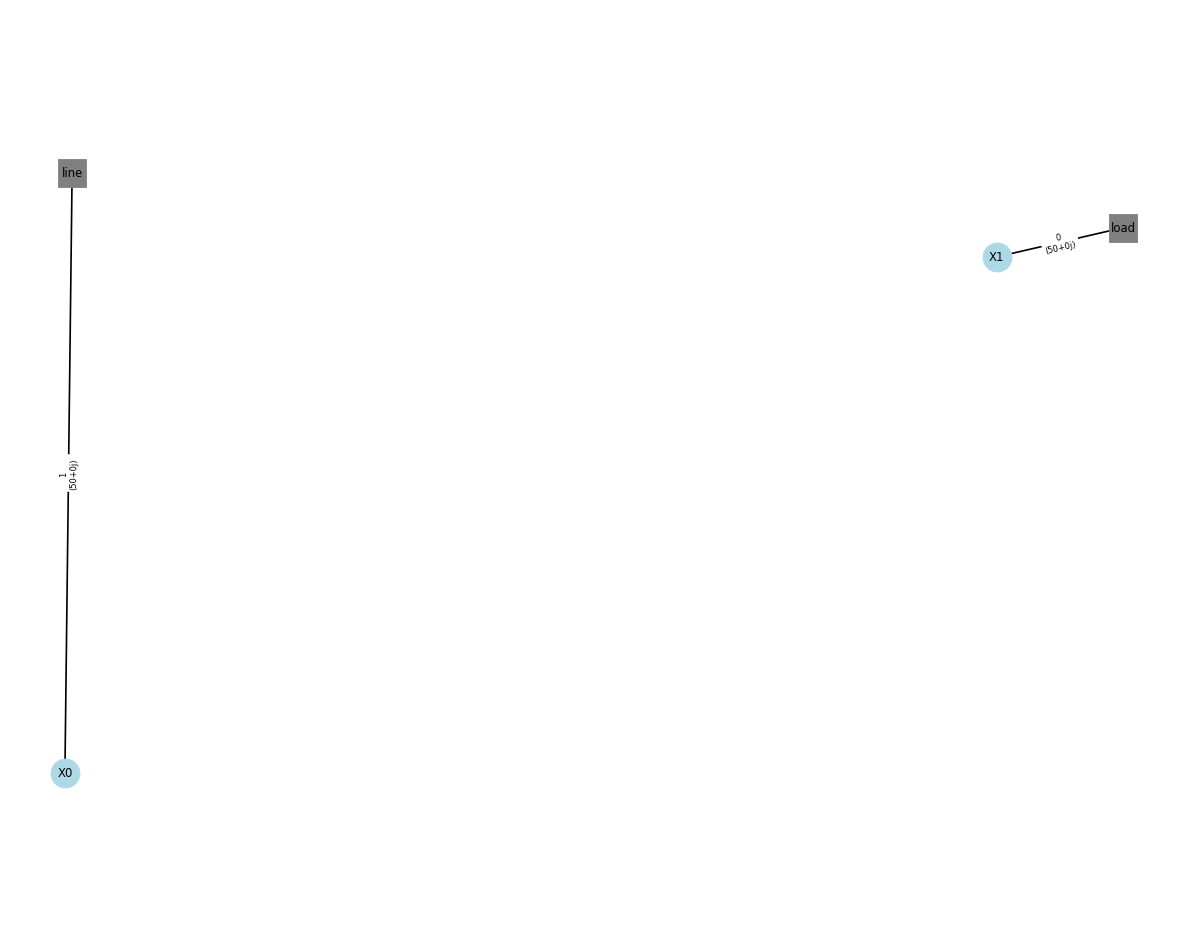

In [13]:
# 3. Define the Circuit
# Connections are lists of tuples: (Network, PortNumber)
# Port 0 of the circuit is connected to line port 0
# Line port 1 is connected to load port 0
connections = [
    [(line, 1)],
    [(load, 0)]
]
# 4. Create the circuit, designating Port 0 of the 'line' as the entry port
# Unconnected ports are implicitly terminated in matched loads (50 ohm)
circuit = Circuit(connections)
# The original example shown above shows two disconnected circuits. 
circuit.plot_graph(network_labels=True,edge_labels=True,port_labels=True,inter_labels=True)

In this version of the circuit we connect the various endpoints together. 

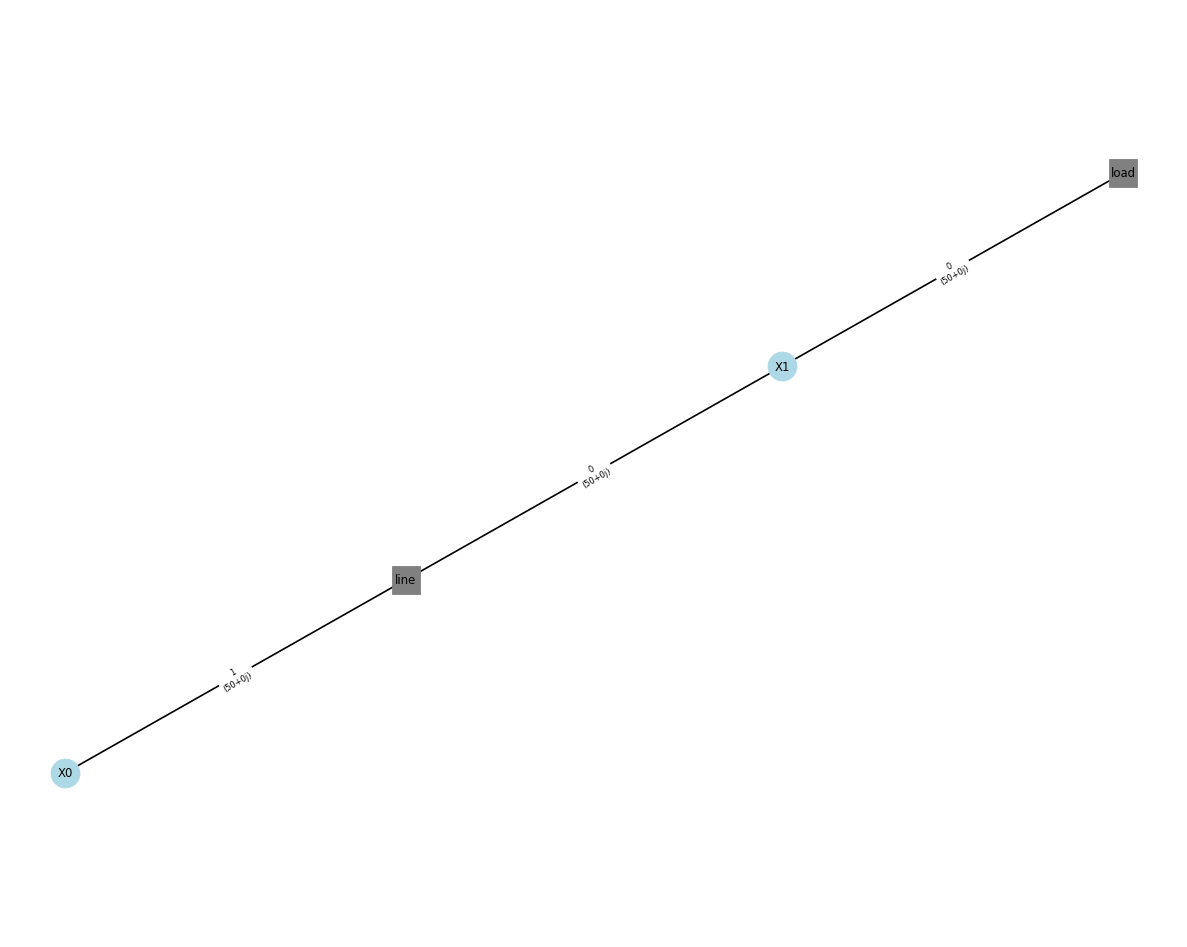

In [8]:
# try this one load is a single port circuit, line is a two port circuit
connections = [
    [(line, 1)],
    [(line, 0), (load,0)]
]
# 4. Create the circuit, designating Port 0 of the 'line' as the entry port
# Unconnected ports are implicitly terminated in matched loads (50 ohm)
circuit = Circuit(connections,'Line-Load')
# The original example shown above shows two disconnected circuits. 
circuit.plot_graph(network_labels=True,port_labels=True,inter_labels=True, edge_labels=True)
# This does not like edge labels on!

IndexError: index 1 is out of bounds for axis 1 with size 1

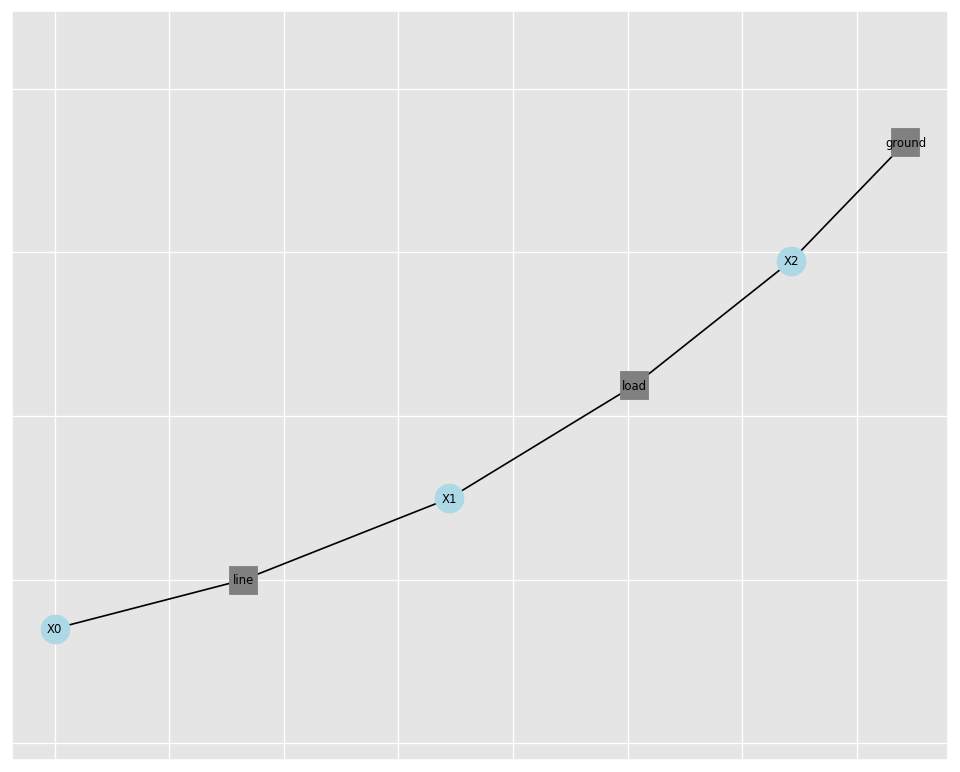

In [3]:
# 3. Define the Circuit ---- MODIFIED A
# Connections are lists of tuples: (Network, PortNumber)
# Port 0 of the circuit is connected to line port 0
# Line port 1 is connected to load port 0
connections = [
    [(line, 0)],
    [(line, 1), (load,1)],
    [(load, 2), (ground,2)]
]
# 4. Create the circuit, designating Port 0 of the 'line' as the entry port
# Unconnected ports are implicitly terminated in matched loads (50 ohm)
circuit = Circuit(connections,'Line-Load')
# The original example shown above shows two disconnected circuits. 
circuit.plot_graph(network_labels=True,port_labels=True,inter_labels=True, edge_labels=True)
# This does not like edge labels on!

In [11]:
circuit.connections

[[(2-Port Network: 'line',  1.0-10.0 GHz, 1001 pts, z0=[50.+0.j 50.+0.j], 1)],
 [(1-Port Network: 'load',  1.0-10.0 GHz, 1001 pts, z0=[50.+0.j], 0)]]

In [6]:

# 5. Extract the 1-port Network
# This is a 1-port network at the input of the circuit (line.port0)
input_network = circuit.network


AxisError: axis 1 is out of bounds for array of dimension 1

In [ ]:
# 6. Plot S11
input_network.plot_s_db(m=0, n=0) # S11 in dB
plt.title('Reflection Coefficient (S11)')
plt.show()